In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

DATASET_PATH = "/content/drive/MyDrive/CVPR_Assignment/flower_images"

print("Dataset Exists:", os.path.exists(DATASET_PATH))

if os.path.exists(DATASET_PATH):
    print("Classes:", os.listdir(DATASET_PATH))

Dataset Exists: True
Classes: ['Lotus', 'Sunflower', 'Lilly', 'Tulip', 'Orchid']


In [5]:
import os

classes = os.listdir(DATASET_PATH)

total_images = 0

for class_name in classes:
    class_path = os.path.join(DATASET_PATH, class_name)

    images = os.listdir(class_path)

    print(class_name, ":", len(images), "images")

    total_images += len(images)

print("\nTotal Images:", total_images)

Lotus : 1000 images
Sunflower : 1000 images
Lilly : 1000 images
Tulip : 1000 images
Orchid : 1000 images

Total Images: 5000


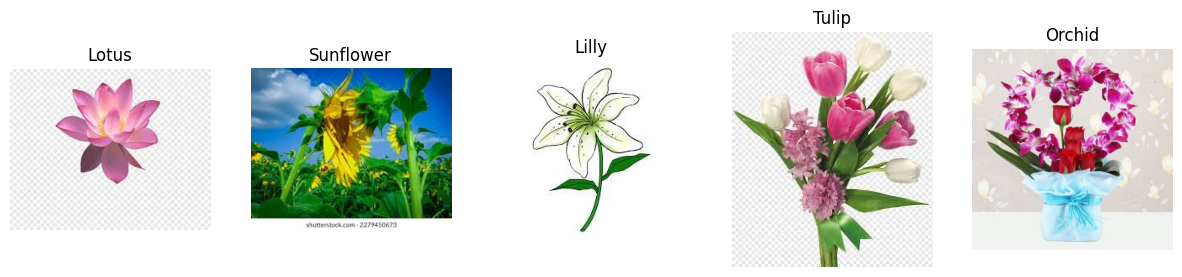

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import random

plt.figure(figsize=(15, 5))

for i, class_name in enumerate(classes):
    class_path = os.path.join(DATASET_PATH, class_name)

    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis('off')

plt.show()

In [7]:
from torchvision import datasets, transforms

# Resize images and convert them into tensors
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

# Load the flower dataset
dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=transform
)

print("Total Images:", len(dataset))
print("Class Names:", dataset.classes)
print("Class Mapping:", dataset.class_to_idx)

Total Images: 4999
Class Names: ['Lilly', 'Lotus', 'Orchid', 'Sunflower', 'Tulip']
Class Mapping: {'Lilly': 0, 'Lotus': 1, 'Orchid': 2, 'Sunflower': 3, 'Tulip': 4}


In [8]:
from torch.utils.data import random_split

# Calculate dataset sizes
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

# Split the dataset
train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size]
)

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))

Training Images: 3499
Validation Images: 749
Testing Images: 751


In [9]:
from torch.utils.data import DataLoader

# Set batch size
batch_size = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 110
Validation Batches: 24
Testing Batches: 24


In [10]:
images, labels = next(iter(train_loader))

print("Image Shape:", images.shape)
print("Label Shape:", labels.shape)

Image Shape: torch.Size([32, 3, 32, 32])
Label Shape: torch.Size([32])


In [11]:
import os

valid_extensions = (
    '.jpg', '.jpeg', '.png', '.ppm',
    '.bmp', '.pgm', '.tif', '.tiff', '.webp'
)

for class_name in os.listdir(DATASET_PATH):

    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):

        unsupported_files = []

        for file in os.listdir(class_path):

            if not file.lower().endswith(valid_extensions):
                unsupported_files.append(file)

        if unsupported_files:
            print(class_name, ":", unsupported_files)

Lilly : ['efa0739yt4jpg']


In [12]:
from PIL import Image
import os

file_path = os.path.join(
    DATASET_PATH,
    "Lilly",
    "efa0739yt4jpg"
)

img = Image.open(file_path)

print("Actual Image Format:", img.format)
print("Image Size:", img.size)

Actual Image Format: JPEG
Image Size: (510, 340)


In [13]:
new_path = file_path + ".jpg"

os.rename(file_path, new_path)

print("File renamed successfully!")

File renamed successfully!


In [14]:
dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=transform
)

print("Total Images:", len(dataset))
print("Classes:", dataset.classes)

Total Images: 5000
Classes: ['Lilly', 'Lotus', 'Orchid', 'Sunflower', 'Tulip']


In [15]:
from torch.utils.data import random_split

# Calculate dataset sizes
train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

# Split the dataset
train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size]
)

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))

Training Images: 3500
Validation Images: 750
Testing Images: 750


In [16]:
from torch.utils.data import DataLoader

# Set batch size
batch_size = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 110
Validation Batches: 24
Testing Batches: 24


In [17]:
images, labels = next(iter(train_loader))

print("Image Shape:", images.shape)
print("Label Shape:", labels.shape)

Image Shape: torch.Size([32, 3, 32, 32])
Label Shape: torch.Size([32])


In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device:", device)

Using Device: cuda


In [19]:
class FlowerCNN(nn.Module):

    def __init__(self):
        super(FlowerCNN, self).__init__()

        # First Convolutional Layer
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)

        # Second Convolutional Layer
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Max Pooling Layer
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully Connected Layers
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 5)

    def forward(self, x):

        # First Convolution + ReLU + Pooling
        x = self.pool(F.relu(self.conv1(x)))

        # Second Convolution + ReLU + Pooling
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten the feature maps
        x = x.view(x.size(0), -1)

        # Fully Connected Layers
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [20]:
model = FlowerCNN()

# Move model to GPU or CPU
model = model.to(device)

print(model)

FlowerCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=5, bias=True)
)


In [21]:
# Get one batch of images
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Pass images through the model
outputs = model(images)

print("Input Shape:", images.shape)
print("Output Shape:", outputs.shape)

Input Shape: torch.Size([32, 3, 32, 32])
Output Shape: torch.Size([32, 5])


In [22]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

print("Loss Function:", criterion)

Loss Function: CrossEntropyLoss()


In [24]:
# Define the Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer: Adam")
print("Learning Rate: 0.001")

# Number of training epochs
num_epochs = 10

print("Number of Epochs:", num_epochs)

Optimizer: Adam
Learning Rate: 0.001
Number of Epochs: 10


In [25]:
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # Validation
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    # Save Results
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 1.2746 Train Accuracy: 46.51% Val Loss: 1.2299 Val Accuracy: 48.27%
Epoch [2/10] Train Loss: 1.0698 Train Accuracy: 57.51% Val Loss: 1.0253 Val Accuracy: 56.80%
Epoch [3/10] Train Loss: 0.9850 Train Accuracy: 61.00% Val Loss: 0.9200 Val Accuracy: 64.00%
Epoch [4/10] Train Loss: 0.9209 Train Accuracy: 64.11% Val Loss: 0.9350 Val Accuracy: 62.40%
Epoch [5/10] Train Loss: 0.8356 Train Accuracy: 68.20% Val Loss: 0.8669 Val Accuracy: 68.00%
Epoch [6/10] Train Loss: 0.7485 Train Accuracy: 71.31% Val Loss: 0.8454 Val Accuracy: 68.00%
Epoch [7/10] Train Loss: 0.6683 Train Accuracy: 74.51% Val Loss: 0.8260 Val Accuracy: 68.93%
Epoch [8/10] Train Loss: 0.5801 Train Accuracy: 78.43% Val Loss: 0.7666 Val Accuracy: 71.73%
Epoch [9/10] Train Loss: 0.4993 Train Accuracy: 81.60% Val Loss: 0.7371 Val Accuracy: 73.07%
Epoch [10/10] Train Loss: 0.4298 Train Accuracy: 84.60% Val Loss: 0.7485 Val Accuracy: 73.20%


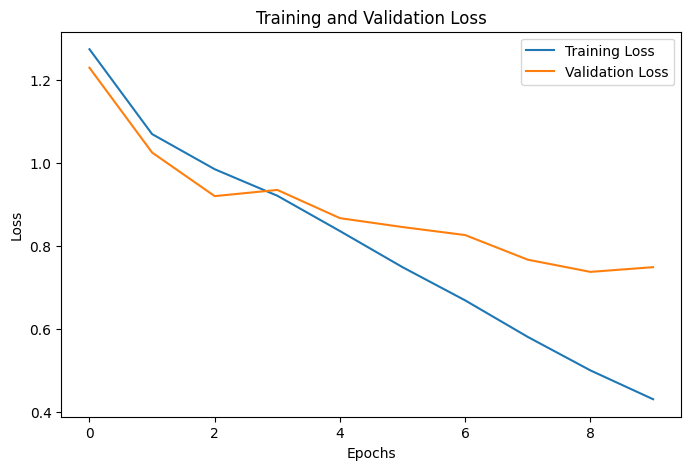

In [26]:
# Plot Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

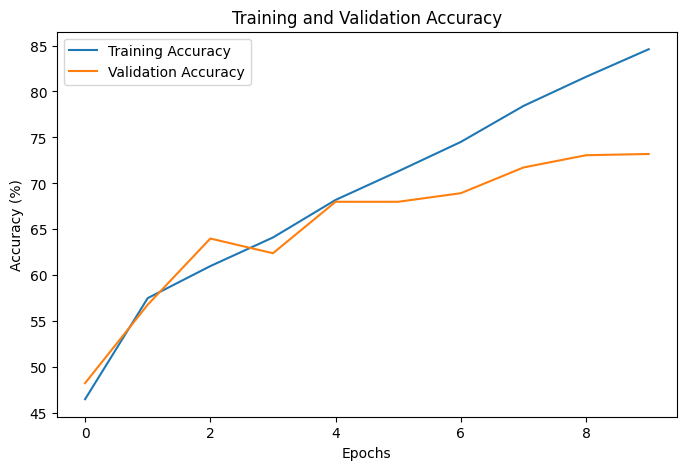

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()

In [28]:
model.eval()

test_loss = 0.0
correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = test_loss / len(test_loader)
test_accuracy = 100 * correct / total

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 2), "%")
print("Total Test Images:", total)

Test Loss: 0.8889
Test Accuracy: 67.87 %
Total Test Images: 750


In [29]:
from sklearn.metrics import classification_report

print("Classification Report:")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes
))

Classification Report:
              precision    recall  f1-score   support

       Lilly       0.57      0.76      0.65       164
       Lotus       0.73      0.60      0.66       136
      Orchid       0.57      0.70      0.63       158
   Sunflower       0.85      0.91      0.88       129
       Tulip       0.86      0.47      0.61       163

    accuracy                           0.68       750
   macro avg       0.72      0.69      0.68       750
weighted avg       0.71      0.68      0.68       750



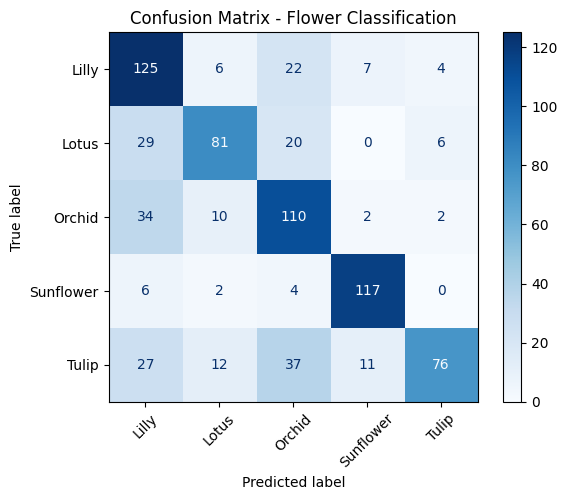

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.classes
)

disp.plot(cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix - Flower Classification")
plt.show()

In [31]:
model_path = "/content/drive/MyDrive/CVPR_Assignment/flower_cnn.pth"

torch.save(model.state_dict(), model_path)

print("Model saved successfully!")
print("Saved Location:", model_path)

Model saved successfully!
Saved Location: /content/drive/MyDrive/CVPR_Assignment/flower_cnn.pth


**Analysis and Discussion :**

The CNN model was trained to classify five types of flowers: Lilly, Lotus, Orchid, Sunflower, and Tulip. The model was trained for 10 epochs using the Adam optimizer with a learning rate of 0.001 and CrossEntropyLoss.

The final training accuracy was 84.60%, while the validation accuracy was 73.20%. On the unseen test dataset containing 750 images, the model achieved an accuracy of 67.87%, with a test loss of 0.8889.

The classification report shows that Sunflower achieved the highest F1-score of 0.88, while Orchid and Lilly achieved F1-scores of 0.63 and 0.65, respectively. Tulip had a recall of 0.47, indicating that the model missed several actual Tulip images.

The confusion matrix shows that the model frequently confused Tulip with Orchid and Lilly. It also confused some Orchid images with Lilly images.

The difference between training accuracy and test accuracy suggests that the model has some overfitting. The model performs better on training images than on unseen test images.

**Conclusion and Future Work :**

In this assignment, a custom Convolutional Neural Network (CNN) was successfully developed to classify five different types of flowers. The model was trained and evaluated using separate training, validation, and test datasets.

The model achieved 67.87% test accuracy. The results demonstrate that the CNN can identify different flower categories, although its performance can still be improved.

In future work, data augmentation, dropout, larger image dimensions, and improved CNN architectures can be explored to reduce overfitting and improve classification accuracy.